# 3 · Q-learning on the grid world

The report's Q-learner did not quite find the optimal policy. On the 7 × 8 world of Figure 1 it
made three "poor decisions", marked in the report's Figure 1b with red arrows, and ended with an
expected reward of 193.9 where the planners reached 199.9. The report blames the missing
exploration parameter:

> "The failure of Q-learning to find the more optimal policy found by both the other algorithms was
> probably due to my not having implemented the ϵ parameter. […] Q-learning got locked into a
> policy too quickly, and ceased to learn."

This notebook rebuilds that learner from the few sentences the report spends on it, and shows that
the rebuilt version makes **the same three mistakes**. That settles what the 2014 learner was
doing. It also shows that exploration was not what went wrong.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import mdplab as ml
from mdplab import plotting as mp
from mdplab import report
from mdplab.gridworld import ARROWS, PIT, REPORT_FIG1B_POLICY

mp.use_style()
pd.options.display.float_format = "{:,.2f}".format

## What the report says about its learner

Three facts can be taken from the text.

1. There was no ϵ: no deliberate random exploration.
2. "My implementation of Q-learning for this MDP requires a minimum of 100·m·n visits to each bin of
   the Q array before checking for policy convergence." For the 7 × 8 world that is 5,600 visits to
   every state-action pair.
3. The run reported for Figure 1 made 1,337,860 updates in total, or 5,973 per entry of the
   7 × 8 × 4 table.

Facts 2 and 3 together say something that fact 1 hides. Every pair was visited at least 5,600
times, and by the report's own count the average was only 7% above that minimum. Whatever rule
chose the pairs, it spread its visits almost perfectly evenly. An agent that was "locked into a policy" in the usual sense,
following its greedy action and starving the alternatives, could not have produced those counts.

So the reconstruction gives every pair exactly the same number of visits: in each sweep, one
transition is sampled for every state-action pair and the Q-learning update

$$Q(s,a) \leftarrow Q(s,a) + \alpha_n \bigl(r + \gamma \max_{a'} Q(s',a') - Q(s,a)\bigr)$$

is applied to each. What the report does not mention is the step size $\alpha_n$. The textbook
choice, and the one the convergence theorem taught in the course asks for, is $\alpha_n = 1/n$ on
the $n$-th visit, which makes $Q(s,a)$ the plain average of all its targets so far. That is the
assumption made here, and the results below are the evidence for it.

In [2]:
world = ml.GridWorld.report_figure1()
mdp = world.mdp
free = world.free
states = np.arange(mdp.n_states)
scorer = ml.PolicyScorer(mdp)  # knows the optimal values, used only for scoring
V_star, Q_star = scorer.V_star, scorer.Q_star

start = time.perf_counter()
runs = ml.synchronous_q_learning(mdp, n_sweeps=5600, alpha=ml.harmonic(), n_runs=50, seed=2014)
seconds = time.perf_counter() - start

updates = 5600 * int(free.sum()) * 4
display(Markdown(
    f"50 independent runs of 5,600 sweeps took **{seconds:.1f} s** in total. Each run makes "
    f"{updates:,} updates (the report counts {report.TABLE_GRIDWORLD.loc['Q-learning', 'iterations']:,} "
    f"over a table that includes the obstacle and pit cells, and took "
    f"{report.TABLE_GRIDWORLD.loc['Q-learning', 'seconds']:.0f} s for its single run)."
))

50 independent runs of 5,600 sweeps took **3.5 s** in total. Each run makes 940,800 updates (the report counts 1,337,860 over a table that includes the obstacle and pit cells, and took 115 s for its single run).

## Figure 1b: the same three mistakes

A learned policy is scored here by what each of its choices costs: the difference between the
optimal value of the cell and the true value of the action it picked there. A choice that gives up
more than 1 (of a possible 200) is called a costly mistake. Smaller differences are near-ties
between equally sensible moves and do not matter.

In [3]:
policies = runs.policies  # (50, 56)
loss = V_star[None, :] - Q_star[states[None, :], policies]
costly = (loss > 1.0) & free[None, :]
flagged_2014 = [(0, 6), (4, 3), (6, 1)]  # the red arrows of Figure 1b

frequency = pd.DataFrame(
    [
        {
            "cell (row, column)": world.cell(s),
            "runs with a costly mistake here (of 50)": int(costly[:, s].sum()),
            "flagged in Figure 1b": world.cell(s) in flagged_2014,
            "value given up": loss[costly[:, s], s].mean(),
        }
        for s in np.flatnonzero(costly.any(axis=0))
    ]
).set_index("cell (row, column)")
frequency

,runs with a costly mistake here (of 50),flagged in Figure 1b,value given up
"cell (row, column)",,,
"(0, 6)",50,True,34.30
"(3, 3)",1,False,2.61
"(4, 3)",49,True,34.31
"(6, 1)",50,True,24.74


In [4]:
only_those = [set(map(world.cell, np.flatnonzero(c))) == set(flagged_2014) for c in costly]
reward = np.array([ml.absorption(mdp, p).total_reward[free].mean() for p in policies])
drawn_1b = world.policy_from_text(REPORT_FIG1B_POLICY)
exact_1b = ml.absorption(mdp, drawn_1b).total_reward[free].mean()
identical = int((policies[:, free] == drawn_1b[free]).all(axis=1).sum())

display(Markdown(
    f"* In **{sum(only_those)} of 50** runs the costly mistakes are exactly the three cells the report flags, and nothing else.\n"
    f"* **{identical}** runs reproduce Figure 1b arrow for arrow in all 42 cells; most of the others differ from it only in near-ties.\n"
    f"* Expected reward of the learned policies: **{reward.mean():.1f}** on average, between {reward.min():.1f} and {reward.max():.1f}. "
    f"The report's simulation gave 193.9; the policy it drew in Figure 1b is worth exactly {exact_1b:.1f}."
))

* In **48 of 50** runs the costly mistakes are exactly the three cells the report flags, and nothing else.
* **5** runs reproduce Figure 1b arrow for arrow in all 42 cells; most of the others differ from it only in near-ties.
* Expected reward of the learned policies: **193.2** on average, between 192.2 and 194.3. The report's simulation gave 193.9; the policy it drew in Figure 1b is worth exactly 193.2.

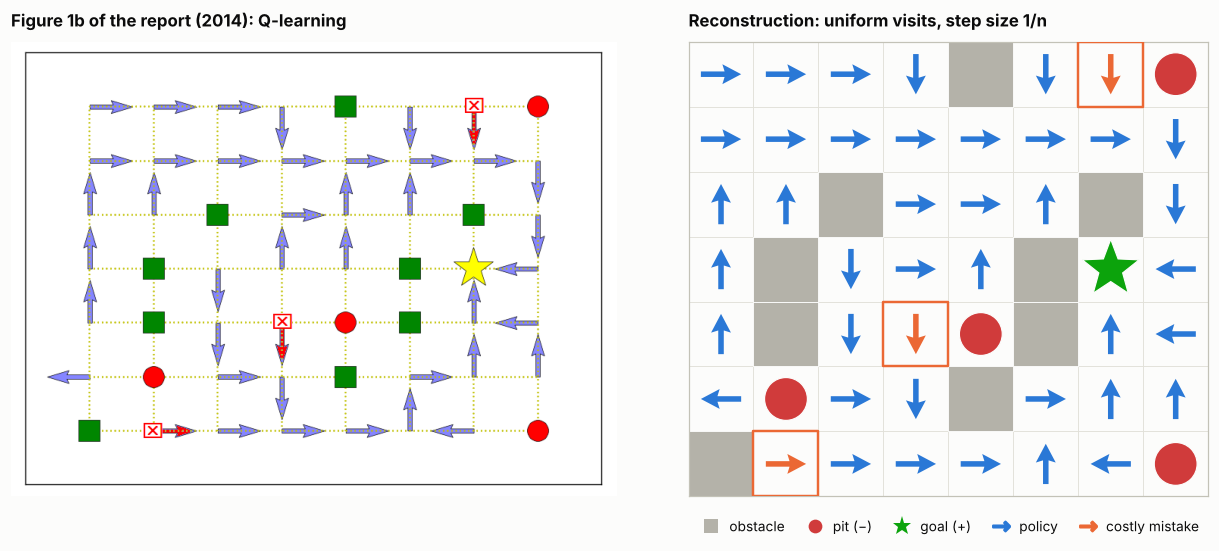

In [5]:
typical = int(np.flatnonzero(only_those)[0])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.9))
mp.show_original("fig1b", axes[0], title="Figure 1b of the report (2014): Q-learning")
mp.plot_gridworld(
    world, policies[typical], flagged=costly[typical], ax=axes[1],
    title="Reconstruction: uniform visits, step size 1/n", flagged_label="costly mistake",
)
mp.savefig(fig, "03_figure1b");

The three mistakes are of one kind. In each of the flagged cells there is a pit next door, the
optimal move steps or pushes away from it, and the learner instead moves *along* the pit, accepting
a one-in-ten chance of slipping in. The report describes exactly this: the planners take "a scenic
route to avoid the red circles", and the learner does not.

## What the learner believed

After 5,600 visits to every pair, a table of learned values exists for every cell. Here it is
for the three flagged cells, beside the truth.

In [6]:
Q_learned = runs.Q.mean(axis=0)
rows_out = []
for cell in flagged_2014:
    s = world.state(*cell)
    best, chosen = int(Q_star[s].argmax()), int(np.bincount(policies[:, s], minlength=4).argmax())
    for role, a in (("optimal move", best), ("move the learner chose", chosen)):
        rows_out.append({"cell": cell, "": role, "move": ARROWS[a], "true value": Q_star[s, a], "learned value (mean of 50 runs)": Q_learned[s, a]})
beliefs = pd.DataFrame(rows_out).set_index(["cell", ""])
beliefs

move  true value  \
cell                                             
(0, 6) optimal move              ←      183.27   
       move the learner chose    ↓      148.97   
(4, 3) optimal move              ←      176.67   
       move the learner chose    ↓      142.35   
(6, 1) optimal move              ↓      165.89   
       move the learner chose    →      141.15   

                               learned value (mean of 50 runs)  
cell                                                            
(0, 6) optimal move                                     106.99  
       move the learner chose                           114.20  
(4, 3) optimal move                                      37.30  
       move the learner chose                            44.24  
(6, 1) optimal move                                      32.80  
       move the learner chose                            43.98

In [7]:
shortfall = 1 - Q_learned[free].max(axis=1) / V_star[free]
display(Markdown(
    f"The learned values are not slightly off. Across the 42 cells, the learner's estimate of a cell's value is on "
    f"average **{shortfall.mean():.0%} below the truth** after 5,600 visits to every pair. In the worst cell, "
    f"whose true value is {V_star[free][shortfall.argmax()]:.0f}, the estimate is still {Q_learned[free].max(axis=1)[shortfall.argmax()]:.1f}."
))

The learned values are not slightly off. Across the 42 cells, the learner's estimate of a cell's value is on average **48% below the truth** after 5,600 visits to every pair. In the worst cell, whose true value is 152, the estimate is still 0.2.

This is the real finding. The policy is nearly right, but the values behind it are nowhere near
converged, and they are all too low. The learner was not locked in; it was still creeping upwards,
extremely slowly. Its three mistakes are the three places where the correct move has a value that
arrives late: the detours and the wait-at-the-wall moves, whose worth depends on a long chain of
later steps all having been learned first.

The cure is not exploration, since every pair was already being visited equally often. Keep
everything the same, same sweeps, same 5,600 visits, and change only the step size from $1/n$ to
$1/n^{0.7}$:

In [8]:
runs_fast = ml.synchronous_q_learning(mdp, n_sweeps=5600, alpha=ml.polynomial(0.7), n_runs=50, seed=2014)
loss_fast = V_star[None, :] - Q_star[states[None, :], runs_fast.policies]
reward_fast = np.array([ml.absorption(mdp, p).total_reward[free].mean() for p in runs_fast.policies])

pd.DataFrame(
    {
        "runs with a costly mistake (of 50)": [int(costly.any(axis=1).sum()), int(((loss_fast > 1.0) & free).any(axis=1).sum())],
        "expected reward, mean": [reward.mean(), reward_fast.mean()],
        "expected reward, worst run": [reward.min(), reward_fast.min()],
    },
    index=pd.Index(["1/n", "1/n^0.7"], name="step size"),
)

,runs with a costly mistake (of 50),"expected reward, mean","expected reward, worst run"
step size,,,
1/n,50,193.17,192.18
1/n^0.7,0,199.91,199.91


With the slower-decaying step size every one of the 50 runs finds a policy worth 199.9, the
optimum. Why one exponent makes this much difference, and what exploration does and does not add
when the agent has to find its own way through the world, is the subject of
[notebook 5](05_step_size_and_exploration.ipynb).

## Figure 4: across world sizes

The report's Figure 4 compares the planned and the learned policies on worlds of 9 to 90 states.

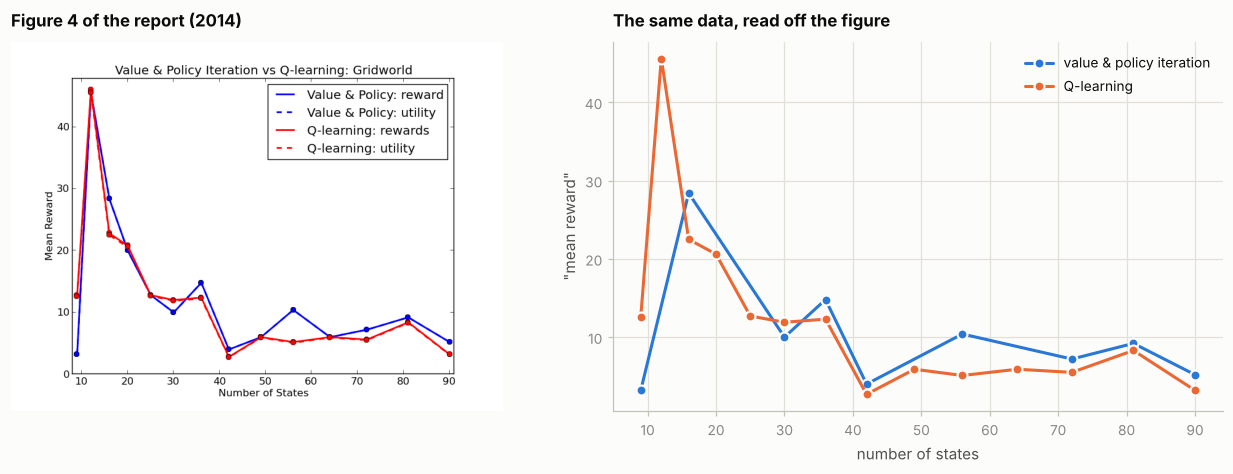

In [9]:
then4 = report.figure4()
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), width_ratios=[1, 1.05])
mp.show_original("fig4", axes[0], title="Figure 4 of the report (2014)")
ax = axes[1]
q = then4.dropna(subset=["q_mean_reward"])
v = then4.dropna(subset=["vi_mean_reward"])
ax.plot(v.states, v.vi_mean_reward, "o-", color=mp.SERIES[0], label="value & policy iteration")
ax.plot(q.states, q.q_mean_reward, "o-", color=mp.SERIES[1], label="Q-learning")
ax.set(xlabel="number of states", ylabel='"mean reward"', title="The same data, read off the figure")
ax.legend();

This figure cannot be reproduced as it stands, for two reasons. Each point is one random world
whose layout is lost. And the quantity on the vertical axis is not defined in the report. It is not
the expected reward of the table above: that is close to 200, and these values lie between 3 and
46 (where a blue marker is missing, it is hidden under the red one). A reward *per move* would have
this size, but there is no way to confirm it.

What can be done is to ask the figure's question again with quantities that are defined. For the
same fourteen sizes, 3 × 3 up to 9 × 10, twelve random worlds each are solved exactly and learned
by the reconstructed 2014 learner, using the report's rule of 100·m·n visits per pair. Policies are
compared by their discounted value from a random starting cell, which is defined for every policy,
and by the probability of ending in a pit.

In [10]:
sizes = [(3, 3), (3, 4), (4, 4), (4, 5), (5, 5), (5, 6), (6, 6), (6, 7), (7, 7), (7, 8), (8, 8), (8, 9), (9, 9), (9, 10)]
rng = np.random.default_rng(4)
records = []
for rows, cols in sizes:
    for _ in range(12):
        w = ml.GridWorld.random(rows, cols, seed=rng)
        if not w.free.any():
            continue
        m = w.mdp
        plan = ml.policy_iteration(m)
        for step_size, schedule in (("1/n", ml.harmonic()), ("1/n^0.7", ml.polynomial(0.7))):
            learned = ml.synchronous_q_learning(m, 100 * rows * cols, alpha=schedule, seed=rng).policies[0]
            records.append({
                "states": rows * cols,
                "step size": step_size,
                "optimal value": plan.V[w.free].mean(),
                "learned value": ml.evaluate_policy(m, learned)[w.free].mean(),
                "pit risk, optimal": ml.hitting_probability(m, plan.policy, w.mask(PIT))[w.free].mean(),
                "pit risk, learned": ml.hitting_probability(m, learned, w.mask(PIT))[w.free].mean(),
            })
sweep = pd.DataFrame(records)
sweep["value lost"] = sweep["optimal value"] - sweep["learned value"]
by_size = sweep.groupby(["step size", "states"]).mean(numeric_only=True)

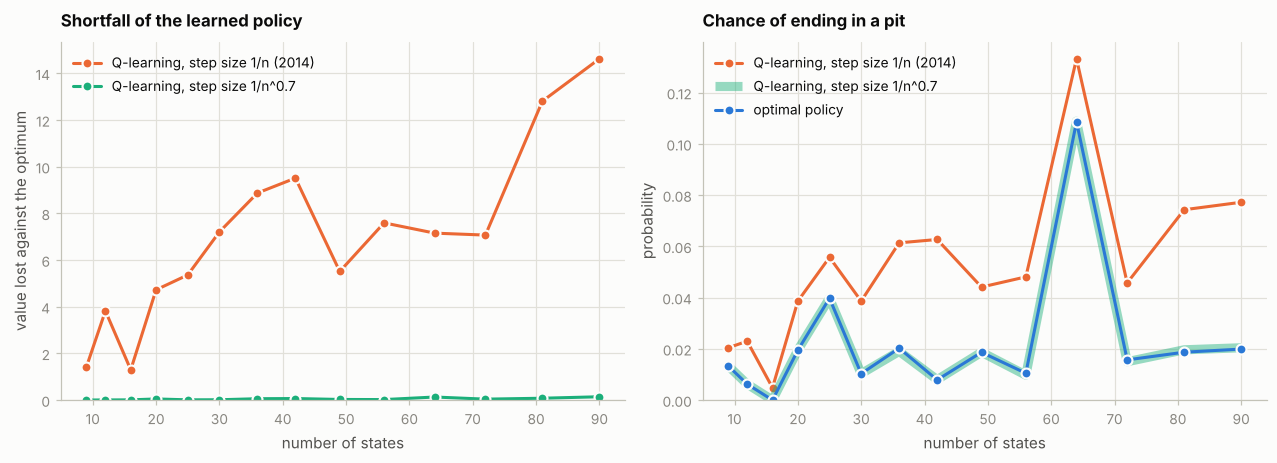

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.1))
for label, colour in (("1/n", mp.SERIES[1]), ("1/n^0.7", mp.SERIES[2])):
    part = by_size.loc[label]
    name = f"Q-learning, step size {label}" + (" (2014)" if label == "1/n" else "")
    axes[0].plot(part.index, part["value lost"], "o-", color=colour, label=name)
    # the 1/n^0.7 learner all but coincides with the optimal policy, so it is drawn as a wide band underneath
    wide = dict(linewidth=6, alpha=0.45, solid_capstyle="butt") if label != "1/n" else dict(marker="o")
    axes[1].plot(part.index, part["pit risk, learned"], color=colour, label=name, **wide)
axes[1].plot(by_size.loc["1/n"].index, by_size.loc["1/n", "pit risk, optimal"], "o-", color=mp.SERIES[0], label="optimal policy")
axes[0].set(xlabel="number of states", ylabel="value lost against the optimum", title="Shortfall of the learned policy")
axes[1].set(xlabel="number of states", ylabel="probability", title="Chance of ending in a pit")
axes[0].set_ylim(bottom=0)
axes[1].set_ylim(bottom=0)
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
mp.savefig(fig, "03_figure4_redone");

In [12]:
overall = sweep.groupby("step size")[["value lost", "pit risk, learned", "pit risk, optimal"]].mean()
overall

,value lost,"pit risk, learned","pit risk, optimal"
step size,,,
1/n,6.93,0.05,0.02
1/n^0.7,0.05,0.02,0.02


The report's summary of this experiment was that "Q-learning was never quite as good as the other
algorithms". The reconstruction agrees, and adds two things. The shortfall of the $1/n$ learner
grows with the size of the world, because larger worlds have longer detours whose value takes
longer to arrive. And almost all of it disappears, at the same cost in samples, when the step
size decays more slowly.

## What was reproduced

| Report | Today |
|---|---|
| Figure 1b: three poor decisions, at (0, 6), (4, 3) and (6, 1) | the same three cells, in 48 of 50 runs exactly those and no others |
| Expected reward 193.9 for the learned policy | 193.2 on average; the drawn policy is worth exactly 193.2 |
| 1,337,860 updates in 115 s | 940,800 updates per run, a fraction of a second |
| Q-learning "never quite as good" as planning (Figure 4) | same, for the 2014 step size; the gap grows with world size |
| Cause: no ϵ | not supported: visits were uniform. A step size of 1/n reproduces the failure, 1/n^0.7 removes it |

The reconstruction rests on one assumption the report does not state, the $1/n$ step size. It is
an inference from the outcome, not a recovered fact: of the step sizes tried in notebook 5, it is
the only one that leaves exactly the three errors of Figure 1b.

Next: [4 · The crazy elevator](04_crazy_elevator.ipynb).